# In-Class Activity: Implementing the Log-Loss (Cross-Entropy) Function

**Course:** CSCN8010 – Statistical Classification and Logistic Regression Workshop
**Author:** Davisen Veerasamy
**Use case:** Predicting whether a student will **Pass (1)** or **Fail (0)** an exam from the number of **hours studied**.

### Goal
In this notebook we implement the **Log-Loss** (a.k.a. **Binary Cross-Entropy**) algorithm from scratch, document every function, and verify it against `scikit-learn`. We then show *why* log-loss matters: it is the quantity that logistic regression **minimises** while it learns its weights.

### Roadmap
1. The data
2. The algorithm, step by step
3. Implementing the building blocks (`sigmoid`, `predict_proba`, `per_sample_log_loss`, `log_loss`)
4. Applying log-loss to a trained logistic regression model
5. Verifying the implementation (hand-calculated example + `sklearn.metrics.log_loss`)
6. Visualising the penalty
7. Training logistic regression by minimising log-loss (gradient descent)
8. Talking points

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss as sk_log_loss, accuracy_score

np.set_printoptions(precision=4, suppress=True)

---
## 1. The Data

The same dataset used in the workshop: 19 students, their study hours ($x$) and whether they passed ($y$).

Note that the data is **not perfectly separable**: the student who studied 2.5 h passed, while the students who studied 2.75 h and 3.25 h failed. Students in this overlap zone are where log-loss will apply its biggest penalties.

In [2]:
hours_studied = np.array([0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75,
                          3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5])
pass_fail = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
                      1, 0, 1, 1, 1, 1, 1, 1, 1])

X = hours_studied.reshape(-1, 1)   # scikit-learn expects a 2-D feature matrix
y = pass_fail

print(f"Number of students: {len(y)}")
print(f"Passed: {y.sum()}  |  Failed: {len(y) - y.sum()}")

Number of students: 19
Passed: 9  |  Failed: 10


---
## 2. The Algorithm, Step by Step

Log-loss measures how well **predicted probabilities** match the **true labels**. For a binary classifier it is computed as follows:

| Step | What happens | Formula |
| :-- | :-- | :-- |
| **1. Linear score** | Combine the input with the model's weights | $z_i = w_0 + w_1 x_i$ |
| **2. Probability** | Squash the score into $(0, 1)$ with the sigmoid | $p_i = \sigma(z_i) = \dfrac{1}{1 + e^{-z_i}}$ |
| **3. Clip** | Keep $p_i$ away from exactly 0 or 1 so that $\log(0)$ never happens | $p_i \leftarrow \text{clip}(p_i,\ \varepsilon,\ 1-\varepsilon)$ |
| **4. Per-sample loss** | Penalise the probability given to the *true* class | $\ell_i = -\left[y_i \log p_i + (1 - y_i)\log(1 - p_i)\right]$ |
| **5. Average** | Summarise over all $N$ samples | $\text{LogLoss} = \dfrac{1}{N}\sum_{i=1}^{N} \ell_i$ |

Step 4 is a compact way of writing the piecewise rule:

$$
\ell_i =
\begin{cases}
-\log(p_i), & y_i = 1 \quad \text{(student passed: only } p_i \text{ matters)}\\
-\log(1 - p_i), & y_i = 0 \quad \text{(student failed: only } 1-p_i \text{ matters)}
\end{cases}
$$

Because one of $y_i$ or $(1-y_i)$ is always 0, exactly one of the two terms "switches off".

**Pseudocode**

```
function LOG_LOSS(y_true, p_pred, eps):
    p ← clip(p_pred, eps, 1 − eps)
    total ← 0
    for i in 1..N:
        if y_true[i] == 1:  total ← total − log(p[i])
        else:               total ← total − log(1 − p[i])
    return total / N
```

Below we implement each step as its own documented function.

---
## 3. Implementing the Building Blocks

### 3.1 `sigmoid(z)` – from score to probability

In [3]:
def sigmoid(z):
    '''
    Map any real number(s) to the open interval (0, 1).

    Parameters
    ----------
    z : float or np.ndarray
        Linear score(s), z = w0 + w1 * x.

    Returns
    -------
    np.ndarray
        Probability that the sample belongs to the positive class (Pass).
    '''
    return 1.0 / (1.0 + np.exp(-z))


# Sanity checks: sigma(0) = 0.5, large positive -> ~1, large negative -> ~0
print(sigmoid(np.array([-10, -2, 0, 2, 10])))

[0.     0.1192 0.5    0.8808 1.    ]


### 3.2 `predict_proba(x, w0, w1)` – the logistic regression model

This combines step 1 (linear score) and step 2 (sigmoid). Given weights, it returns the probability of passing for each student.

In [4]:
def predict_proba(x, w0, w1):
    '''
    Probability of the positive class for a one-feature logistic regression.

    Parameters
    ----------
    x  : np.ndarray  Input feature values (hours studied), shape (N,).
    w0 : float       Intercept (bias).
    w1 : float       Coefficient (weight) of the feature.

    Returns
    -------
    np.ndarray  p_i = sigmoid(w0 + w1 * x_i), shape (N,).
    '''
    z = w0 + w1 * np.asarray(x, dtype=float)
    return sigmoid(z)

### 3.3 `per_sample_log_loss(y_true, y_prob)` – steps 3 and 4

We implement the **compact formula** and also a **piecewise** version written with `np.where`, to show that both give identical results.

**Why clip?** If a model ever predicts exactly $p = 0$ for a student who passed, $-\log(0) = \infty$ and the loss would explode. Clipping to $[\varepsilon, 1-\varepsilon]$ with $\varepsilon = 10^{-15}$ caps the worst possible penalty at $-\log(10^{-15}) \approx 34.5$.

In [5]:
EPS = 1e-15


def per_sample_log_loss(y_true, y_prob, eps=EPS):
    '''
    Log-loss of every individual sample (compact formula).

    Parameters
    ----------
    y_true : np.ndarray  True binary labels (0 or 1), shape (N,).
    y_prob : np.ndarray  Predicted probabilities of class 1, shape (N,).
    eps    : float       Clipping constant that prevents log(0).

    Returns
    -------
    np.ndarray  l_i = -[y_i*log(p_i) + (1 - y_i)*log(1 - p_i)], shape (N,).
    '''
    y_true = np.asarray(y_true, dtype=float)
    y_prob = np.clip(np.asarray(y_prob, dtype=float), eps, 1 - eps)
    return -(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))


def per_sample_log_loss_piecewise(y_true, y_prob, eps=EPS):
    '''Same as per_sample_log_loss, written as the piecewise rule (for teaching).'''
    y_prob = np.clip(np.asarray(y_prob, dtype=float), eps, 1 - eps)
    return np.where(np.asarray(y_true) == 1, -np.log(y_prob), -np.log(1 - y_prob))

### 3.4 `log_loss(y_true, y_prob)` – step 5, the dataset-level score

In [6]:
def log_loss(y_true, y_prob, eps=EPS):
    '''
    Average binary log-loss (cross-entropy) over a dataset.

    Parameters
    ----------
    y_true : np.ndarray  True binary labels (0 or 1).
    y_prob : np.ndarray  Predicted probabilities of class 1.
    eps    : float       Clipping constant that prevents log(0).

    Returns
    -------
    float  Mean of the per-sample losses. Lower is better; 0 is perfect.
    '''
    return float(np.mean(per_sample_log_loss(y_true, y_prob, eps)))

---
## 4. Applying Log-Loss to a Trained Logistic Regression Model

We train the same `LogisticRegression()` as in the workshop, take its predicted probabilities, and evaluate them with **our** `log_loss` function.

We also use our own `predict_proba` with the model's learned weights, to confirm that we understand exactly how `scikit-learn` produces its probabilities.

In [7]:
model = LogisticRegression()          # default settings, as in the workshop
model.fit(X, y)

w0 = model.intercept_[0]
w1 = model.coef_[0][0]
print(f"Learned weights: w0 (intercept) = {w0:.4f}, w1 (coefficient) = {w1:.4f}")

p_sklearn = model.predict_proba(X)[:, 1]               # P(Pass) from scikit-learn
p_ours = predict_proba(hours_studied, w0, w1)          # P(Pass) from our function
print("Our predict_proba matches scikit-learn:", np.allclose(p_sklearn, p_ours))

losses = per_sample_log_loss(y, p_ours)
print("Compact and piecewise formulas agree:  ",
      np.allclose(losses, per_sample_log_loss_piecewise(y, p_ours)))

Learned weights: w0 (intercept) = -4.5166, w1 (coefficient) = 1.5676
Our predict_proba matches scikit-learn: True
Compact and piecewise formulas agree:   True


### 4.1 Per-student breakdown

The table shows, for every student, the probability the model assigned to passing, the probability it assigned to the **true** outcome, and the resulting loss.

In [8]:
y_hat = (p_ours >= 0.5).astype(int)   # decision threshold of 0.5

print(f"{'Hours':>5} | {'y':>1} | {'P(Pass)':>7} | {'P(true class)':>13} | {'Loss':>6} | Correct?")
print("-" * 60)
for x_i, y_i, p_i, l_i, yh_i in zip(hours_studied, y, p_ours, losses, y_hat):
    p_true = p_i if y_i == 1 else 1 - p_i
    flag = "yes" if yh_i == y_i else "NO  <-- misclassified"
    print(f"{x_i:5.2f} | {y_i:1d} | {p_i:7.3f} | {p_true:13.3f} | {l_i:6.3f} | {flag}")

print("-" * 60)
print(f"Total loss   = {losses.sum():.4f}")
print(f"Average loss = {log_loss(y, p_ours):.4f}   (N = {len(y)})")
print(f"Accuracy     = {accuracy_score(y, y_hat) * 100:.2f}%")

Hours | y | P(Pass) | P(true class) |   Loss | Correct?
------------------------------------------------------------
 0.50 | 0 |   0.023 |         0.977 |  0.024 | yes
 0.75 | 0 |   0.034 |         0.966 |  0.035 | yes
 1.00 | 0 |   0.050 |         0.950 |  0.051 | yes
 1.25 | 0 |   0.072 |         0.928 |  0.075 | yes
 1.50 | 0 |   0.103 |         0.897 |  0.109 | yes
 1.75 | 0 |   0.145 |         0.855 |  0.157 | yes
 2.00 | 0 |   0.201 |         0.799 |  0.224 | yes
 2.25 | 0 |   0.271 |         0.729 |  0.316 | yes
 2.50 | 1 |   0.355 |         0.355 |  1.036 | NO  <-- misclassified
 2.75 | 0 |   0.449 |         0.551 |  0.596 | yes
 3.00 | 1 |   0.546 |         0.546 |  0.604 | yes
 3.25 | 0 |   0.641 |         0.359 |  1.023 | NO  <-- misclassified
 3.50 | 1 |   0.725 |         0.725 |  0.321 | yes
 3.75 | 1 |   0.796 |         0.796 |  0.228 | yes
 4.00 | 1 |   0.852 |         0.852 |  0.160 | yes
 4.25 | 1 |   0.895 |         0.895 |  0.111 | yes
 4.50 | 1 |   0.927 |         0

**Observations**
- Students far from the decision boundary (e.g. 0.5 h → Fail, 5 h → Pass) get small losses: the model is confident *and* correct.
- The two largest losses (≈ 1.0 each) belong to the two **misclassified** students: 2.5 h (passed) and 3.25 h (failed). The model gave their true outcome only ≈ 36 % probability.
- Students close to the decision boundary (2.75 h and 3 h) are classified correctly, but with only ≈ 55 % confidence. They still pay a noticeable loss (≈ 0.6). Log-loss rewards correct answers only as much as the model is sure of them.
- Accuracy only counts right/wrong, whereas log-loss also takes **confidence** into account. Two models can have the same accuracy but very different log-loss.

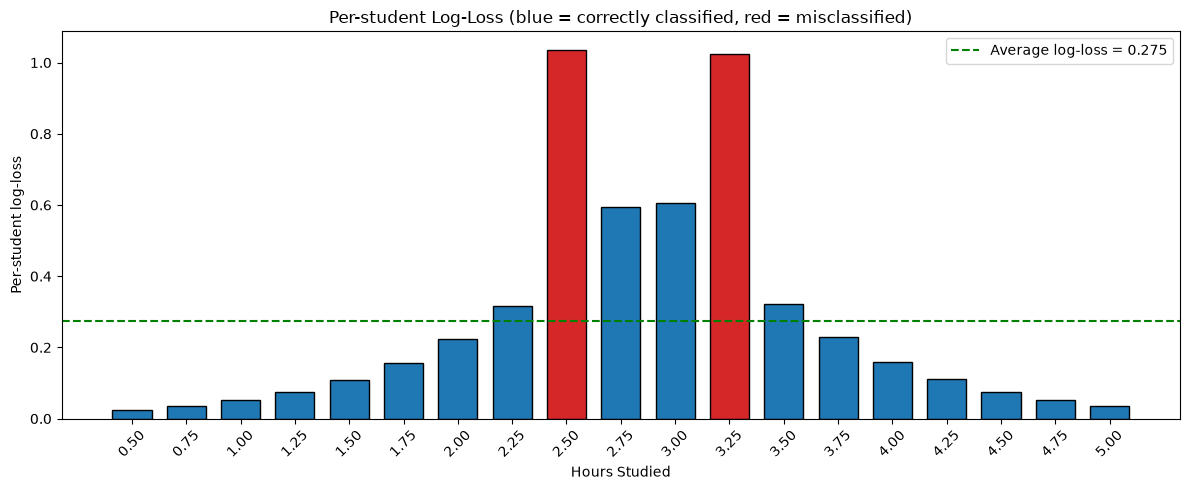

In [9]:
colors = np.where(y_hat == y, "tab:blue", "tab:red")

plt.figure(figsize=(12, 5))
plt.bar(hours_studied, losses, width=0.18, color=colors, edgecolor="k")
plt.axhline(log_loss(y, p_ours), color="green", linestyle="--",
            label=f"Average log-loss = {log_loss(y, p_ours):.3f}")
plt.xlabel("Hours Studied")
plt.ylabel("Per-student log-loss")
plt.title("Per-student Log-Loss (blue = correctly classified, red = misclassified)")
plt.xticks(hours_studied, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

---
## 5. Verifying the Implementation

A from-scratch implementation is only useful if it is correct. We verify it two ways.

### 5.1 Against the hand-calculated example from the workshop

| Hours | $y$ | $p$ | Loss |
| :-- | :-- | :-- | --: |
| 1.0 | 0 | 0.12 | 0.128 |
| 2.5 | 1 | 0.45 | 0.799 |
| 4.5 | 1 | 0.96 | 0.041 |
| 2.75 | 0 | 0.60 | 0.916 |

Expected average log-loss: **0.471**.

In [10]:
y_example = np.array([0, 1, 1, 0])
p_example = np.array([0.12, 0.45, 0.96, 0.60])

print("Per-sample losses:", per_sample_log_loss(y_example, p_example).round(3))
print(f"Average log-loss : {log_loss(y_example, p_example):.3f}  (expected 0.471)")

Per-sample losses: [0.128 0.799 0.041 0.916]
Average log-loss : 0.471  (expected 0.471)


### 5.2 Against `sklearn.metrics.log_loss`

In [11]:
ours = log_loss(y, p_ours)
reference = sk_log_loss(y, p_sklearn)

print(f"Our log_loss       : {ours:.10f}")
print(f"sklearn log_loss   : {reference:.10f}")
print("Match:", np.isclose(ours, reference))

Our log_loss       : 0.2753945936
sklearn log_loss   : 0.2753945936
Match: True


### 5.3 Edge case: why clipping matters
A model that is **100 % sure and wrong** would produce an infinite loss without clipping.

In [12]:
with np.errstate(divide="ignore"):
    unclipped = -np.log(0.0)        # student passed, model said P(Pass) = 0
print(f"Without clipping: {unclipped}")
print(f"With clipping   : {log_loss([1], [0.0]):.4f}  (= -log(1e-15))")

Without clipping: inf


With clipping   : 34.5388  (= -log(1e-15))


---
## 6. Visualising the Penalty

The penalty grows **slowly** while the prediction is roughly right, and **explodes** as the model becomes confidently wrong. This asymmetry is what pushes a model to produce honest, well-calibrated probabilities.

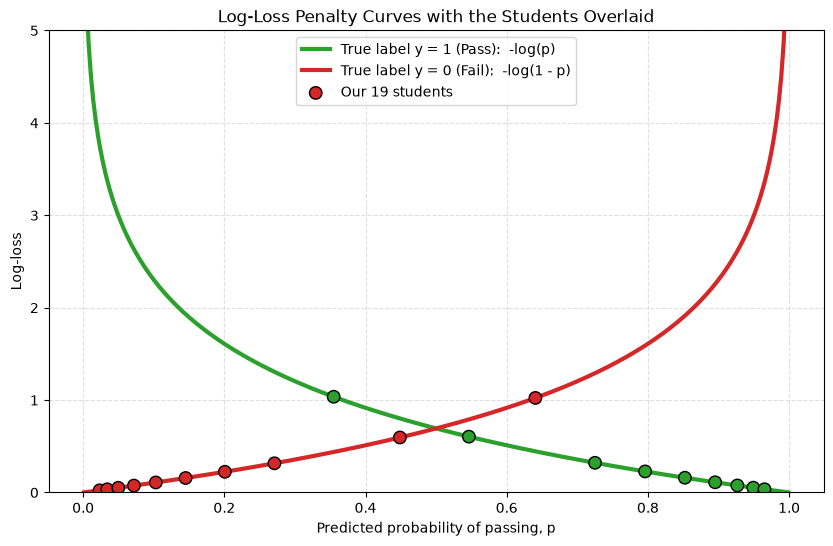

In [13]:
p_grid = np.linspace(0.001, 0.999, 300)

plt.figure(figsize=(10, 6))
plt.plot(p_grid, per_sample_log_loss(np.ones_like(p_grid), p_grid),
         color="tab:green", lw=3, label="True label y = 1 (Pass):  -log(p)")
plt.plot(p_grid, per_sample_log_loss(np.zeros_like(p_grid), p_grid),
         color="tab:red", lw=3, label="True label y = 0 (Fail):  -log(1 - p)")

# Overlay the actual students on their curves
plt.scatter(p_ours, losses, c=np.where(y == 1, "tab:green", "tab:red"),
            edgecolor="k", s=80, zorder=5, label="Our 19 students")

plt.xlabel("Predicted probability of passing, p")
plt.ylabel("Log-loss")
plt.title("Log-Loss Penalty Curves with the Students Overlaid")
plt.ylim(0, 5)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.show()

---
## 7. Training Logistic Regression by Minimising Log-Loss

So far we used log-loss to **evaluate** a model. More importantly, log-loss is the **objective** that logistic regression minimises while it learns $w_0$ and $w_1$.

### 7.1 The gradient
For the average log-loss $L(w_0, w_1)$, the derivative simplifies to the elegant expression:

$$
\frac{\partial L}{\partial w_0} = \frac{1}{N}\sum_{i=1}^{N}(p_i - y_i)
\qquad
\frac{\partial L}{\partial w_1} = \frac{1}{N}\sum_{i=1}^{N}(p_i - y_i)\,x_i
$$

$(p_i - y_i)$ is simply the **prediction error**. This works because $\sigma'(z) = \sigma(z)(1-\sigma(z))$ cancels out the denominators of the log terms.

### 7.2 Gradient descent
Starting from $w_0 = w_1 = 0$ (every student gets $p = 0.5$), we repeatedly step against the gradient:

$$
w_j \leftarrow w_j - \eta \frac{\partial L}{\partial w_j}
$$

where $\eta$ is the learning rate.

In [14]:
def log_loss_gradient(x, y_true, w0, w1):
    '''
    Gradient of the average log-loss with respect to (w0, w1).

    Returns
    -------
    tuple(float, float)  (dL/dw0, dL/dw1)
    '''
    error = predict_proba(x, w0, w1) - y_true      # p_i - y_i
    return error.mean(), (error * x).mean()


def fit_logistic_regression(x, y_true, learning_rate=0.5, n_iters=20_000):
    '''
    Learn (w0, w1) by gradient descent on the average log-loss.

    Returns
    -------
    w0, w1 : float   Learned intercept and coefficient.
    history : list   Log-loss after every iteration (to plot convergence).
    '''
    w0, w1 = 0.0, 0.0
    history = []
    for _ in range(n_iters):
        g0, g1 = log_loss_gradient(x, y_true, w0, w1)
        w0 -= learning_rate * g0
        w1 -= learning_rate * g1
        history.append(log_loss(y_true, predict_proba(x, w0, w1)))
    return w0, w1, history


gd_w0, gd_w1, history = fit_logistic_regression(hours_studied, y)

print(f"Initial log-loss (w0 = w1 = 0): {log_loss(y, predict_proba(hours_studied, 0, 0)):.4f}  (= log 2)")
print(f"Final log-loss                : {history[-1]:.4f}")
print(f"Gradient-descent weights      : w0 = {gd_w0:.4f}, w1 = {gd_w1:.4f}")

Initial log-loss (w0 = w1 = 0): 0.6931  (= log 2)
Final log-loss                : 0.2321
Gradient-descent weights      : w0 = -8.5383, w1 = 2.9696


### 7.3 Comparing with scikit-learn

`LogisticRegression()` uses **L2 regularisation by default** (`C=1.0`). It minimises *log-loss + a penalty on large weights*, so its weights are smaller than the pure log-loss minimum. Setting `C=np.inf` turns regularisation off, and then `scikit-learn` should agree with our gradient descent.

In [15]:
model_unreg = LogisticRegression(C=np.inf).fit(X, y)

rows = [
    ("Our gradient descent", gd_w0, gd_w1),
    ("sklearn, C=np.inf (no regularisation)", model_unreg.intercept_[0], model_unreg.coef_[0][0]),
    ("sklearn, default (L2, C=1.0)", w0, w1),
]
print(f"{'Model':<40} {'w0':>9} {'w1':>8} {'log-loss':>9} {'boundary (h)':>13}")
print("-" * 83)
for name, a, b in rows:
    ll = log_loss(y, predict_proba(hours_studied, a, b))
    print(f"{name:<40} {a:9.4f} {b:8.4f} {ll:9.4f} {-a / b:13.3f}")

Model                                           w0       w1  log-loss  boundary (h)
-----------------------------------------------------------------------------------
Our gradient descent                       -8.5383   2.9696    0.2321         2.875
sklearn, C=np.inf (no regularisation)      -8.5400   2.9703    0.2321         2.875
sklearn, default (L2, C=1.0)               -4.5166   1.5676    0.2754         2.881


The unregularised models reach the **lowest possible log-loss** on this data. The regularised default accepts a slightly higher training log-loss in exchange for smaller, more conservative weights, which usually generalises better to new students. All three put the decision boundary ($p = 0.5$, i.e. $x = -w_0/w_1$) at roughly the same number of hours.

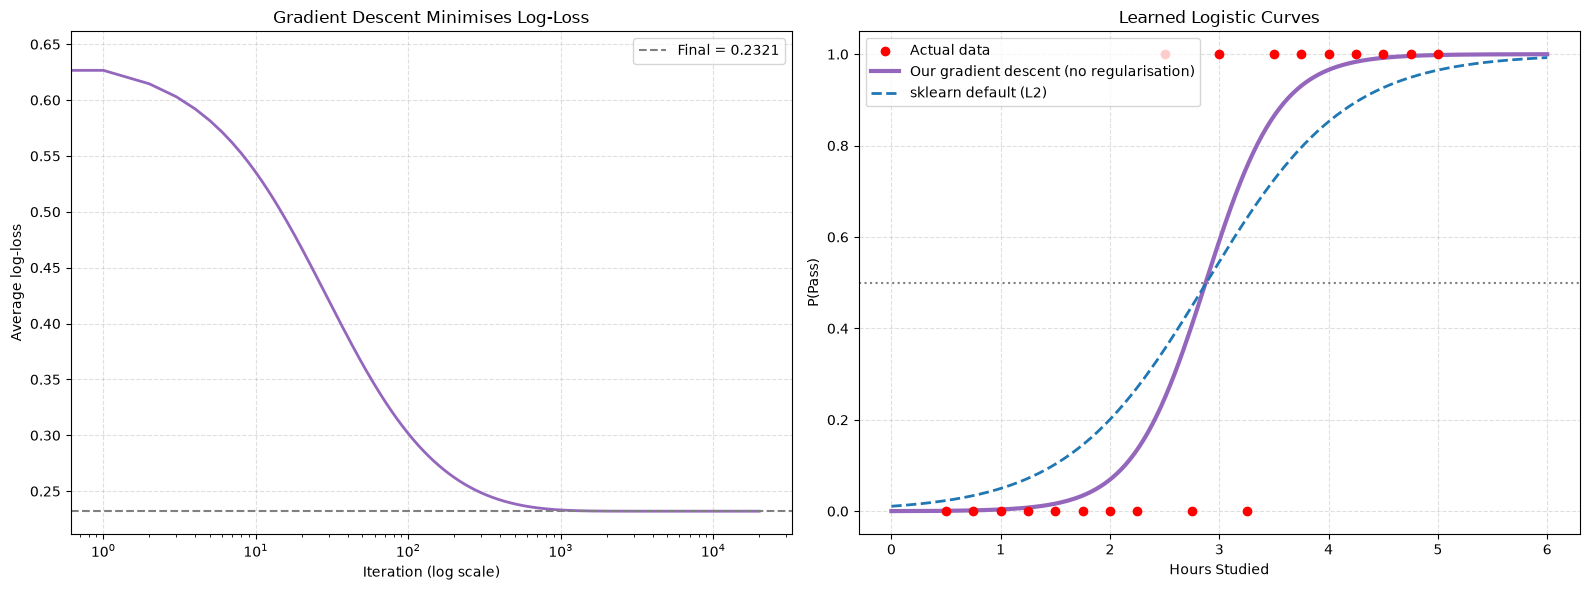

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left: convergence of gradient descent
ax1.plot(history, color="tab:purple", lw=2)
ax1.axhline(history[-1], color="grey", linestyle="--", label=f"Final = {history[-1]:.4f}")
ax1.set_xscale("log")
ax1.set_xlabel("Iteration (log scale)")
ax1.set_ylabel("Average log-loss")
ax1.set_title("Gradient Descent Minimises Log-Loss")
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend()

# Right: the resulting S-curves
x_plot = np.linspace(0, 6, 300)
ax2.scatter(hours_studied, y, color="red", zorder=5, label="Actual data")
ax2.plot(x_plot, predict_proba(x_plot, gd_w0, gd_w1), color="tab:purple", lw=3,
         label="Our gradient descent (no regularisation)")
ax2.plot(x_plot, predict_proba(x_plot, w0, w1), color="tab:blue", lw=2, linestyle="--",
         label="sklearn default (L2)")
ax2.axhline(0.5, color="grey", linestyle=":")
ax2.set_xlabel("Hours Studied")
ax2.set_ylabel("P(Pass)")
ax2.set_title("Learned Logistic Curves")
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

---
## 8. Talking Points

### Talking Point 1: Log-loss scores *confidence*, not just correctness (Sections 2–4)
- The core function `per_sample_log_loss` is one line, $-[y\log p + (1-y)\log(1-p)]$, and it is the compact form of the piecewise rule. Only the probability given to the **true** class matters, and the `y` / `1 - y` factors switch the irrelevant term off.
- The per-student table shows that the biggest losses (≈ 1.0) come from the two misclassified students (2.5 h passed, 3.25 h failed). Correct but unsure predictions near the boundary (2.75 h, 3 h) still cost ≈ 0.6. Accuracy only counts right vs. wrong; log-loss also measures *how confident* the model was.
- Because $-\log p$ grows without limit as $p \to 0$, a model that is **confidently wrong** pays far more than one that is unsure. This pushes the model towards honest, calibrated probabilities.

### Talking Point 2: Numerical safety and verification (Sections 3.3 and 5)
- `np.clip(p, eps, 1 - eps)` prevents $\log(0) = -\infty$. Without it, one over-confident wrong prediction would make the whole dataset's loss infinite. With $\varepsilon = 10^{-15}$ the worst single penalty is capped at about 34.5.
- We did not just trust our code. It reproduces the workshop's hand-calculated result (**0.471**), it matches `sklearn.metrics.log_loss` to 10 decimal places, and our `predict_proba` reproduces `scikit-learn`'s probabilities from the learned weights.
- The averaged form ($\frac{1}{N}\sum$) makes the loss comparable across datasets of different sizes.

### Talking Point 3: Log-loss is what logistic regression *learns from* (Section 7)
- The gradient of log-loss is the simple error term $(p_i - y_i)$ (times $x_i$ for the weight). With that, a 10-line gradient-descent loop trains the model from scratch.
- Starting at $w_0 = w_1 = 0$ (loss $= \log 2 \approx 0.693$, a coin flip), gradient descent drives the loss down to the same minimum `scikit-learn` finds with `C=np.inf`.
- The default `LogisticRegression()` gives *different* weights because it adds **L2 regularisation**. This is a deliberate trade-off: slightly higher training loss for smaller weights and better generalisation. It is easy to miss if you only call `.fit()`.

---
## Summary

| Function | Role in the algorithm |
| :-- | :-- |
| `sigmoid(z)` | Converts a linear score into a probability in $(0, 1)$ |
| `predict_proba(x, w0, w1)` | The logistic regression model: $\sigma(w_0 + w_1 x)$ |
| `per_sample_log_loss(y, p)` | Clips $p$ and computes $-[y\log p + (1-y)\log(1-p)]$ for each sample |
| `log_loss(y, p)` | Averages the per-sample losses into one score for the dataset |
| `log_loss_gradient(x, y, w0, w1)` | Computes the gradient of the log-loss: mean error and mean error × feature |
| `fit_logistic_regression(x, y)` | Gradient descent that learns $w_0, w_1$ by minimising log-loss |

Log-loss is both the **report card** (evaluation metric) and the **teacher** (training objective) of logistic regression.